# 03 · A small CNN, augmentation and pad-style training data

Questions:
1. How much of the gap from notebook 02 does a **small CNN** close on its own?
2. How much do **augmentations** add (rotation/zoom/shift, stroke thickness via erosion and
   dilation, binarisation)?
3. How much does **domain-matched synthetic data** add: MNIST *training* digits redrawn with the
   pad's pen (`pad_skel_train`, notebook 01)?
4. Is the improvement from the architecture or from the data? (Train the MLP on the same data.)

The `pad_tmpl` set (different stroke generator, unseen writers) is never used for training or
model selection, so it is the honest out-of-distribution number. All models train for the same
budget: 8 epochs × 470 steps of batch 128, Adam with cosine decay.

In [1]:
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from scipy.ndimage import rotate

import datasets, models, synth
import evaluate as ev
from browser import render_strokes, preprocess_to_mnist

plt.rcParams['figure.dpi'] = 80
keras.utils.set_random_seed(42)
MODEL_DIR = datasets.CACHE / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

x_train, y_train, _, _ = datasets.load_mnist()
x_mn = x_train.astype(np.float32) / 255
x_pad, y_pad = datasets.pad_skeleton_set(x_train, y_train, 'pad_skel_train', seed=1)
sets = ev.load_test_sets()

## Training runs

| run | model | data |
|---|---|---|
| `mlp_deployed` | the shipped MLP (notebook 02) | MNIST |
| `cnn_mnist` | CNN | MNIST, no augmentation |
| `cnn_aug` | CNN | MNIST + augmentation |
| `cnn_aug_pad` | CNN | ½ MNIST + augmentation, ½ pad-pen MNIST + light affine |
| `cnn16_aug_pad` | CNN at half width | same as above |
| `mlp_aug_pad` | MLP (deployed architecture) | same as above |

Trained models are cached in `cache/models/`; delete them to retrain.

In [2]:
EPOCHS, STEPS = 8, 470
RUNS = {
    'cnn_mnist':     (lambda: models.build_cnn('cnn_mnist'), [(x_mn, y_train, None, 1.0)]),
    'cnn_aug':       (lambda: models.build_cnn('cnn_aug'), [(x_mn, y_train, models.augment_mnist, 1.0)]),
    'cnn_aug_pad':   (lambda: models.build_cnn('cnn_aug_pad'),
                      [(x_mn, y_train, models.augment_mnist, 0.5), (x_pad, y_pad, models.augment_light, 0.5)]),
    'cnn16_aug_pad': (lambda: models.build_cnn('cnn16_aug_pad', width=16),
                      [(x_mn, y_train, models.augment_mnist, 0.5), (x_pad, y_pad, models.augment_light, 0.5)]),
    'mlp_aug_pad':   (lambda: models.build_mlp('mlp_aug_pad'),
                      [(x_mn, y_train, models.augment_mnist, 0.5), (x_pad, y_pad, models.augment_light, 0.5)]),
}
trained, train_time = {}, {}
for name, (build, sources) in RUNS.items():
    path = MODEL_DIR / f'{name}.keras'
    if path.exists():
        trained[name] = keras.models.load_model(path)
        continue
    keras.utils.set_random_seed(42)
    m = build()
    t0 = time.time()
    models.train(m, models.make_train_ds(sources), STEPS, EPOCHS, verbose=0)
    train_time[name] = time.time() - t0
    m.save(path)
    trained[name] = m
    print(f'{name}: trained in {train_time[name] / 60:.1f} min')

C:\Users\alext\AppData\Local\Temp\claude\C--Projects-Math-Run--claude-worktrees-cnn-research-145fc2\fa7b1b91-843d-4754-953e-2c5e055544bc\scratchpad\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


cnn_mnist: trained in 4.5 min


cnn_aug: trained in 4.8 min


cnn_aug_pad: trained in 4.8 min


cnn16_aug_pad: trained in 1.9 min


mlp_aug_pad: trained in 0.5 min


In [3]:
mlp_sm = tf.saved_model.load('../saved_model').signatures['serving_default']
def mlp_deployed(x, batch=2048):
    x = x.reshape(len(x), 784).astype(np.float32)
    return np.concatenate([mlp_sm(keras_tensor=tf.constant(x[i:i + batch]))['output_0'].numpy()
                           for i in range(0, len(x), batch)])

predictors = {'mlp_deployed': mlp_deployed, **{k: models.predict_fn(m) for k, m in trained.items()}}
params = {'mlp_deployed': 435_404, **{k: m.count_params() for k, m in trained.items()}}

## Results

In [4]:
results = {name: ev.accuracy_table(f, sets) for name, f in predictors.items()}
cols = list(sets)
print(f'{"run":15s} {"params":>8s} ' + ' '.join(f'{c:>10s}' for c in cols))
for name, r in results.items():
    print(f'{name:15s} {params[name]:8,d} ' + ' '.join(f'{r[c]:10.2%}' for c in cols))

run               params      mnist mnist_pipe   pad_skel   pad_tmpl
mlp_deployed     435,404     98.28%     97.97%     93.90%     92.88%
cnn_mnist        106,730     99.28%     99.06%     96.45%     94.11%
cnn_aug          106,730     99.12%     99.14%     96.61%     94.58%
cnn_aug_pad      106,730     99.20%     99.12%     97.40%     95.03%
cnn16_aug_pad     28,378     98.59%     98.64%     96.05%     94.10%
mlp_aug_pad      435,402     98.56%     98.34%     96.02%     95.29%


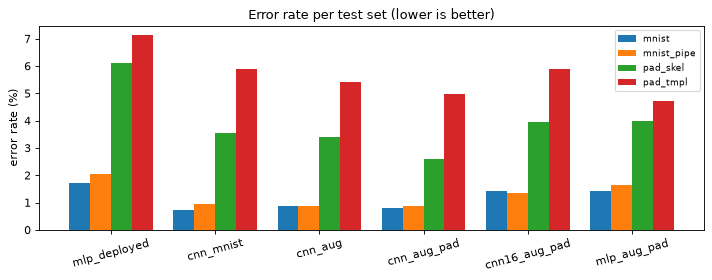

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
names = list(results)
w = 0.8 / len(cols)
for j, c in enumerate(cols):
    err = [100 * (1 - results[n][c]) for n in names]
    ax.bar(np.arange(len(names)) + j * w, err, w, label=c)
ax.set_xticks(np.arange(len(names)) + w * (len(cols) - 1) / 2, names, rotation=15)
ax.set_ylabel('error rate (%)'); ax.set_title('Error rate per test set (lower is better)')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Confidence of mistakes and what the player sees

In [6]:
best = 'cnn_aug_pad'
for name in ['mlp_deployed', best]:
    for s in ['pad_skel', 'pad_tmpl']:
        x, y = sets[s]
        p = predictors[name](x)
        ok, conf = p.argmax(1) == y, p.max(1)
        hit, wrong, other = ev.game_hit_rate(p, y, 1)
        print(f'{name:13s} {s:9s} wrong & >90% confident: {(~ok & (conf > 0.9)).mean():5.1%}   '
              f'game accepts (1 answer on screen): {hit:6.1%}')

mlp_deployed  pad_skel  wrong & >90% confident:  3.9%   game accepts (1 answer on screen):  94.8%


mlp_deployed  pad_tmpl  wrong & >90% confident:  4.3%   game accepts (1 answer on screen):  94.0%


cnn_aug_pad   pad_skel  wrong & >90% confident:  0.8%   game accepts (1 answer on screen):  98.3%


cnn_aug_pad   pad_tmpl  wrong & >90% confident:  1.1%   game accepts (1 answer on screen):  96.8%


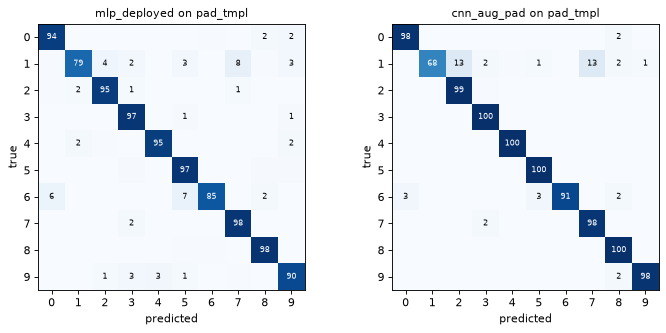

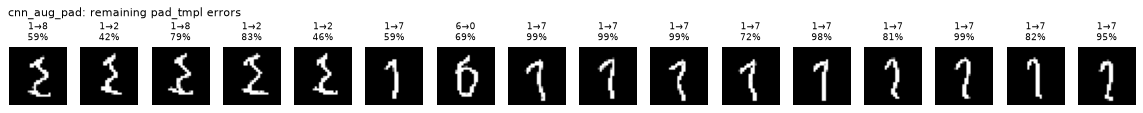

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
x, y = sets['pad_tmpl']
for a, name in zip(ax, ['mlp_deployed', best]):
    ev.plot_confusion(y, predictors[name](x).argmax(1), f'{name} on pad_tmpl', a)
plt.tight_layout(); plt.show()
p = predictors[best](x)
ev.show_errors(x, y, p.argmax(1), p, title=f'{best}: remaining pad_tmpl errors')

## Robustness sweeps

Left: rotate the `pad_skel` test images. Right: change the pen width used by `renderForModel()`
(the game uses 18 px); useful if the pad rendering is ever retuned.

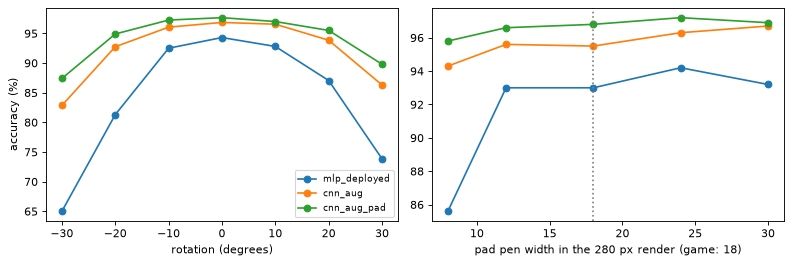

mlp_deployed  rotation ±30°: 65.0% / 73.9%   pen 8 px: 85.6%  pen 30 px: 93.2%
cnn_aug       rotation ±30°: 82.8% / 86.3%   pen 8 px: 94.3%  pen 30 px: 96.7%
cnn_aug_pad   rotation ±30°: 87.4% / 89.8%   pen 8 px: 95.8%  pen 30 px: 96.9%


In [8]:
rng = np.random.default_rng(0)
xs, ys = sets['pad_skel']
idx = rng.choice(len(xs), 2000, replace=False)
angles = [-30, -20, -10, 0, 10, 20, 30]
rot_acc = {n: [] for n in ['mlp_deployed', 'cnn_aug', best]}
for a in angles:
    xr = np.stack([rotate(im, a, reshape=False, order=1) for im in xs[idx]])
    for n in rot_acc:
        rot_acc[n].append((predictors[n](xr).argmax(1) == ys[idx]).mean())

_, _, x_test, y_test = datasets.load_mnist()
sub = rng.choice(len(x_test), 1000, replace=False)
sk = [synth.skeleton_strokes(x_test[i], np.random.default_rng(int(i))) for i in sub]
lines = [8, 12, 18, 24, 30]
line_acc = {n: [] for n in rot_acc}
for lw in lines:
    xl = np.stack([preprocess_to_mnist(render_strokes(s, line=lw)) for s in sk])
    for n in line_acc:
        line_acc[n].append((predictors[n](xl).argmax(1) == y_test[sub]).mean())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for n in rot_acc:
    ax[0].plot(angles, np.array(rot_acc[n]) * 100, 'o-', label=n)
    ax[1].plot(lines, np.array(line_acc[n]) * 100, 'o-', label=n)
ax[0].set_xlabel('rotation (degrees)'); ax[0].set_ylabel('accuracy (%)'); ax[0].legend(fontsize=8)
ax[1].set_xlabel('pad pen width in the 280 px render (game: 18)'); ax[1].axvline(18, color='gray', ls=':')
plt.tight_layout(); plt.show()
for n in rot_acc:
    print(f'{n:13s} rotation ±30°: {rot_acc[n][0]:.1%} / {rot_acc[n][-1]:.1%}   '
          f'pen 8 px: {line_acc[n][0]:.1%}  pen 30 px: {line_acc[n][-1]:.1%}')

## Size and speed

CPU latency here is Keras/TF in Python (batch 1) and only shows relative cost. The browser
number that matters (TF.js WASM, the backend the game prefers) is measured with
`export/bench.html`; see the README.

In [9]:
def cpu_latency(f, n=200):
    x = np.random.rand(1, 28, 28).astype(np.float32)
    for _ in range(10): f(x)
    t0 = time.perf_counter()
    for _ in range(n): f(x)
    return (time.perf_counter() - t0) / n * 1000

fast = {'mlp_deployed': lambda x: mlp_sm(keras_tensor=tf.constant(x.reshape(1, 784)))}
for n in ['cnn_aug_pad', 'cnn16_aug_pad']:
    fn = tf.function(lambda x, m=trained[n]: m(x, training=False))
    fast[n] = lambda x, fn=fn: fn(tf.constant(x[..., None]))
for n, f in fast.items():
    print(f'{n:14s} params {params[n]:8,d}   float32 weights {params[n] * 4 / 1024:6.0f} KB   '
          f'TF CPU batch-1 latency {cpu_latency(f):.2f} ms')

mlp_deployed   params  435,404   float32 weights   1701 KB   TF CPU batch-1 latency 0.80 ms


cnn_aug_pad    params  106,730   float32 weights    417 KB   TF CPU batch-1 latency 2.67 ms


cnn16_aug_pad  params   28,378   float32 weights    111 KB   TF CPU batch-1 latency 2.16 ms


## Export to TF.js (research copy, not the game's model)

Same route as the deployed model: Keras → SavedModel → `tensorflowjs_converter`
(graph model). Output: `export/cnn_tfjs/` (float32) and `export/cnn_tfjs_f16/` (float16 weights,
half the download). The game's `mnist_tfjs_model/` is untouched. The input is
`[batch, 28, 28, 1]` instead of the MLP's `[batch, 784]`, so shipping it would need a one-line
reshape in `recognizer.js`.

In [10]:
import shutil
from tensorflowjs.converters import tf_saved_model_conversion_v2 as tfjs_conv

EXPORT = Path('export')
for name, out, quant in [(best, 'cnn_tfjs', None), (best, 'cnn_tfjs_f16', {'float16': '*'}),
                         ('cnn16_aug_pad', 'cnn16_tfjs', None)]:
    sm = datasets.CACHE / f'saved_{name}'
    trained[name].export(str(sm), verbose=False)
    shutil.rmtree(EXPORT / out, ignore_errors=True)
    tfjs_conv.convert_tf_saved_model(str(sm), str(EXPORT / out), signature_def='serving_default',
                                     saved_model_tags='serve', quantization_dtype_map=quant)
    size = sum(f.stat().st_size for f in (EXPORT / out).iterdir())
    print(f'{out:14s} {size / 1024:6.0f} KB on disk')
print('deployed MLP  ', f"{sum(f.stat().st_size for f in Path('../../mnist_tfjs_model').iterdir()) / 1024:6.0f} KB on disk")

C:\Users\alext\AppData\Local\Temp\claude\C--Projects-Math-Run--claude-worktrees-cnn-research-145fc2\fa7b1b91-843d-4754-953e-2c5e055544bc\scratchpad\venv\Lib\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


INFO:tensorflow:Assets written to: C:\Projects\Math-Run\.claude\worktrees\cnn-research-145fc2\mlp_training\research\cache\saved_cnn_aug_pad\assets


INFO:tensorflow:Assets written to: C:\Projects\Math-Run\.claude\worktrees\cnn-research-145fc2\mlp_training\research\cache\saved_cnn_aug_pad\assets


cnn_tfjs          431 KB on disk


INFO:tensorflow:Assets written to: C:\Projects\Math-Run\.claude\worktrees\cnn-research-145fc2\mlp_training\research\cache\saved_cnn_aug_pad\assets


INFO:tensorflow:Assets written to: C:\Projects\Math-Run\.claude\worktrees\cnn-research-145fc2\mlp_training\research\cache\saved_cnn_aug_pad\assets


cnn_tfjs_f16      223 KB on disk


INFO:tensorflow:Assets written to: C:\Projects\Math-Run\.claude\worktrees\cnn-research-145fc2\mlp_training\research\cache\saved_cnn16_aug_pad\assets


INFO:tensorflow:Assets written to: C:\Projects\Math-Run\.claude\worktrees\cnn-research-145fc2\mlp_training\research\cache\saved_cnn16_aug_pad\assets


cnn16_tfjs        125 KB on disk
deployed MLP     1706 KB on disk


In [11]:
# keep a few test inputs with the expected outputs so the browser benchmark can check the export
xb, yb = sets['pad_tmpl'][0][:32], sets['pad_tmpl'][1][:32]
pb = predictors[best](xb)
import json
(EXPORT / 'check_inputs.json').write_text(json.dumps({
    'x': np.round(xb, 4).reshape(32, -1).tolist(), 'y': yb.tolist(),
    'cnn_probs': np.round(pb, 5).tolist(), 'mlp_probs': np.round(mlp_deployed(xb), 5).tolist()}))

136807

## 小结

结论（数字见上表，README 中有汇总）：
- **数据比架构更重要**：只把 MLP 换成 CNN（`cnn_mnist`）能减少一部分 pad 风格上的错误；
  加上增强、再加上"用游戏笔重画的 MNIST"后错误率大幅下降。同样的数据喂给 MLP（`mlp_aug_pad`）
  也会明显变好，但 CNN 在 `pad_tmpl`（从未参与训练/选择的新字形）上仍然更好、参数量却只有 MLP 的约 1/4。
- 高置信度错误明显减少，旋转和笔宽变化下也更稳健。
- 导出的 TF.js 模型比现在的 MLP 小得多（float16 版本更小），浏览器 WASM 延迟见 README。